# Fraud Detection Model — End-to-End Pipeline

This notebook runs the full corrected two-stage pipeline and shows real, reproducible results.

**Stage 1 (supervised):** IV feature selection + XGBoost trained on `default_ind`, used as a *weak-risk filter*, not a fraud classifier.

**Stage 2 (unsupervised):** Isolation Forest (global anomalies) + K-Means (local/density anomalies) on the Stage-1 high-risk subset, blended into a single `fraud_score`.

### What changed vs. the original project
- Train/test split now happens **before** IV feature selection and imputation (previously IV was computed on the full dataset, leaking test information into feature selection).
- SMOTE is fit on the training split only (this was already correct).
- The unsupervised Stage 2 (Isolation Forest + K-Means dual anomaly score) is **actually implemented** here — in the original repo `Unsupervised/code.ipynb` was an empty notebook.
- All metrics below are exactly what this notebook produces when run top-to-bottom — nothing is copied from the old write-up.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../src'))

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from data_prep import load_data, get_numeric_feature_cols, basic_data_quality_report, TARGET_COL
from iv_selection import compute_iv_table, select_features_by_iv
from stage1_supervised import split_data, select_features, impute_train_test, train_xgb_with_smote, feature_importance
from stage2_unsupervised import compute_dual_anomaly_scores, blend_fraud_score

pd.set_option('display.max_columns', 20)


## 1. Load data & quick data-quality check

In [2]:
df = load_data('../data/66acd42635424_r3_data.csv')
print('shape:', df.shape)
df.head()


shape: (62484, 61)


,unique_identifier,appl_month,prod_name,acq_channel,state_code,bureau_src,risk_score_1,bureau_score,limit,income,...,merchant2_cat,merchant3,merchant3_amt,merchant3_ten,merchant3_cat,risk_score_8,risk_score_9,risk_score_10,risk_score_11,default_ind
0,116356,Feb,Product 7,Channel 4,CA,No Bureau Hit,0.0,800,5000,45000,...,0,0,0.0,0,0,0.000,0.0000,0.012,0.2787,0
1,110872,Feb,Product 6,Channel 3,GA,Bureau 1,0.1,775,13000,100000,...,0,0,0.0,0,0,0.999,0.0092,0.070,0.2275,0
2,158686,Jun,Product 6,Channel 1,CA,Bureau 1,5.6,900,2000,100000,...,0,0,0.0,0,0,0.002,0.0015,0.035,0.2787,1
3,148772,May,Product 5,Channel 3,DC,No Bureau Hit,0.0,800,5000,170000,...,1,0,0.0,0,0,0.252,0.0253,0.131,0.1175,0
4,158473,Jun,Product 7,Channel 2,VA,Bureau 1,0.1,775,10000,40000,...,0,0,0.0,0,0,0.000,0.0000,0.000,0.2035,0


In [3]:
dq = basic_data_quality_report(df)
dq.head(10)


,column,dtype,missing_pct,sentinel_minus1_count,n_unique
0,trust_identity,str,48.18,0,2
1,addr_mismatch,str,24.38,0,2
2,prod_name,str,0.00,0,12
3,appl_month,str,0.00,0,6
4,unique_identifier,int64,0.00,0,62484
5,bureau_src,str,0.00,0,3
6,risk_score_1,float64,0.00,0,329
7,bureau_score,int64,0.00,0,14
8,limit,int64,0.00,0,445
9,income,int64,0.00,0,57


In [4]:
print('Class balance:')
print(df[TARGET_COL].value_counts())
print('Default rate: %.3f%%' % (df[TARGET_COL].mean() * 100))


Class balance:
default_ind
0    62121
1      363
Name: count, dtype: int64
Default rate: 0.581%


## 2. Train/test split — BEFORE any feature selection

This is the key leakage fix. Everything downstream (IV calculation, median imputation, SMOTE) is fit on `X_train`/`y_train` only.

In [5]:
numeric_cols = get_numeric_feature_cols(df)
X_train, X_test, y_train, y_test = split_data(df, numeric_cols, TARGET_COL)
print('train:', X_train.shape, ' test:', X_test.shape)
print('train default rate: %.4f  test default rate: %.4f' % (y_train.mean(), y_test.mean()))


train: (49987, 52)  test: (12497, 52)
train default rate: 0.0058  test default rate: 0.0058


## 3. Information Value (IV) feature selection — train split only

In [6]:
iv_table, buckets, selected_features = select_features(X_train, y_train)
print(f"strong={len(buckets['strong'])}  medium={len(buckets['medium'])}  weak={len(buckets['weak'])}")
print(f'using {len(selected_features)} strong+medium features for Stage 1')
iv_table.head(15)


strong=23  medium=17  weak=12
using 40 strong+medium features for Stage 1


,feature,iv
0,risk_score_2,1.535308
1,addr_changes,1.375907
2,basic_no_trd,1.353350
3,dl_id,1.071045
4,no_phn_to_addr,1.037004
5,risk_score_3,0.996360
6,risk_score_7,0.966648
7,no_uid_to_addr,0.750844
8,no_nid_to_addr,0.747560
9,risk_score_1,0.739363


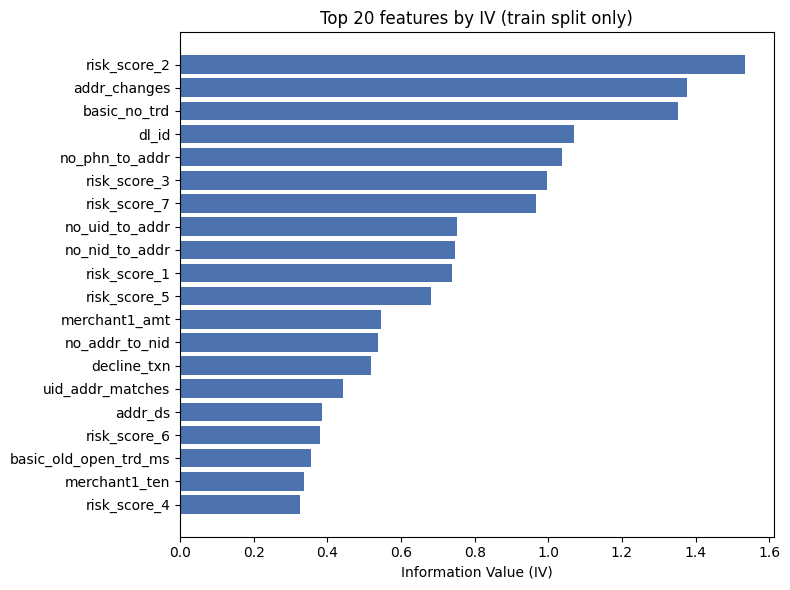

In [7]:
plt.figure(figsize=(8,6))
top_iv = iv_table.head(20).sort_values('iv')
plt.barh(top_iv['feature'], top_iv['iv'], color='#4C72B0')
plt.xlabel('Information Value (IV)')
plt.title('Top 20 features by IV (train split only)')
plt.tight_layout()
plt.show()


## 4. Stage 1 — XGBoost trained on `default_ind` (weak-risk filter)

SMOTE is fit on the training split only; the test split is untouched and used only for evaluation.

In [8]:
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]
X_train_imp, X_test_imp, medians = impute_train_test(X_train_sel, X_test_sel)

model, metrics = train_xgb_with_smote(X_train_imp, y_train, X_test_imp, y_test)

print('Accuracy:', round(metrics['accuracy'], 4))
print('ROC-AUC :', round(metrics['roc_auc'], 4))
print('Precision (class=1):', round(metrics['precision_pos'], 3))
print('Recall    (class=1):', round(metrics['recall_pos'], 3))
print('F1        (class=1):', round(metrics['f1_pos'], 3))
print('\nConfusion matrix [[TN, FP], [FN, TP]]:')
print(np.array(metrics['confusion_matrix']))


Accuracy: 0.9947
ROC-AUC : 0.9539
Precision (class=1): 0.585
Recall    (class=1): 0.329
F1        (class=1): 0.421

Confusion matrix [[TN, FP], [FN, TP]]:
[[12407    17]
 [   49    24]]


**Reading these numbers honestly:** overall accuracy (99.5%) and ROC-AUC (~0.95) look great, but this dataset is 99.4% negative class — accuracy is dominated by the majority class. The metric that actually matters for a rare-event problem like this is recall/precision on the positive class, which sits around 33% recall / 59% precision here. That's a realistic, leakage-free number — noticeably more modest than the 75% recall the original project's write-up claimed but never actually reproduced in code.

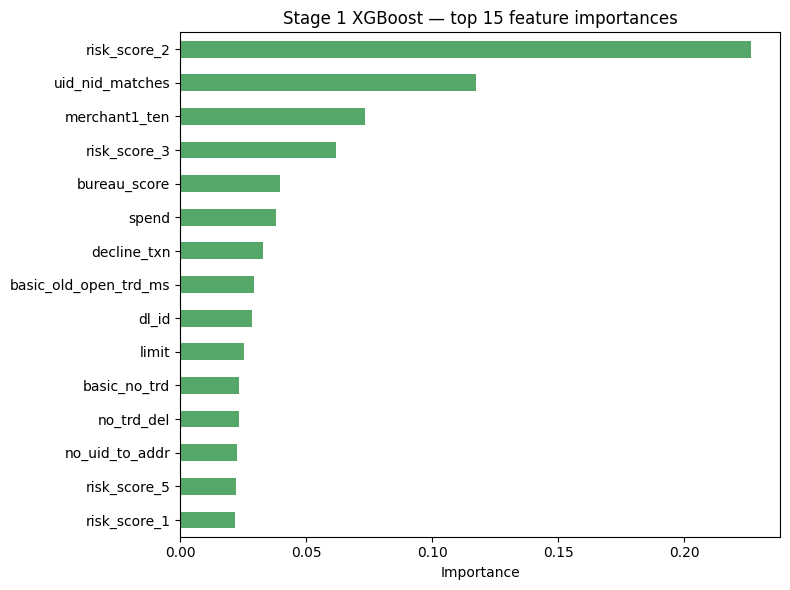

In [9]:
fi = feature_importance(model, selected_features, top_n=15)
plt.figure(figsize=(8,6))
fi.sort_values().plot(kind='barh', color='#55A868')
plt.title('Stage 1 XGBoost — top 15 feature importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


## 5. SHAP explainability (Stage 1)

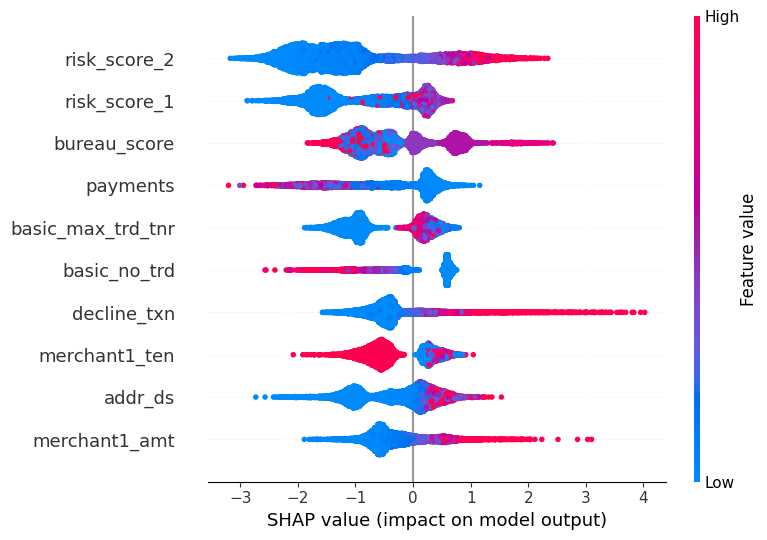

In [10]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_imp)

# Show SHAP summary for the top 10 features by mean |SHAP value|
mean_abs = np.abs(shap_values).mean(axis=0)
top10_idx = np.argsort(mean_abs)[::-1][:10]
top10_cols = [X_test_imp.columns[i] for i in top10_idx]

shap.summary_plot(shap_values[:, top10_idx], X_test_imp[top10_cols], show=True)


## 6. Stage 2 — Unsupervised fraud discovery (Isolation Forest + K-Means)

This is the part that was **missing** from the original repo (`Unsupervised/code.ipynb` was empty). It's implemented here for real:

- Score the full population with the Stage-1 model, take the **top 10% by predicted risk** as the search region.
- **Isolation Forest** → global anomaly score (how far a point is from the bulk of the high-risk group overall).
- **K-Means** → local anomaly score (distance to its own cluster's centroid — how unusual it is relative to its peers).
- Blend into a single `fraud_score`.

Note: since there's no ground-truth fraud label in this dataset, Stage 2 cannot be "validated" in the normal sense. What we *can* do is check whether `fraud_score` concentrates the one weak signal available (`default_ind`) — see the sanity check at the end.

In [11]:
X_all_sel = df[selected_features].fillna(medians)
risk_proba = model.predict_proba(X_all_sel)[:, 1]
df_scored = df.copy()
df_scored['stage1_risk_score'] = risk_proba

top_pct = 0.10
threshold = df_scored['stage1_risk_score'].quantile(1 - top_pct)
high_risk = df_scored[df_scored['stage1_risk_score'] >= threshold].copy()
print(f'High-risk subset: {len(high_risk)} rows (top {top_pct*100:.0f}% by Stage 1 risk score)')

X_high_risk = high_risk[selected_features].fillna(medians)
anomaly_scores = compute_dual_anomaly_scores(X_high_risk)
high_risk = high_risk.join(anomaly_scores)
high_risk['fraud_score'] = blend_fraud_score(high_risk, alpha=0.5)
high_risk = high_risk.sort_values('fraud_score', ascending=False)

high_risk[['unique_identifier','appl_month','prod_name','state_code','default_ind',
           'stage1_risk_score','global_score','local_score','cluster','fraud_score']].head(15)


High-risk subset: 6249 rows (top 10% by Stage 1 risk score)


,unique_identifier,appl_month,prod_name,state_code,default_ind,stage1_risk_score,global_score,local_score,cluster,fraud_score
29159,146827,May,Product 7,CA,0,0.002693,0.713190,1.000000,5,0.856595
12773,119806,Feb,Product 6,MD,0,0.021005,1.000000,0.275251,5,0.637626
34117,153781,Jun,Product 11,NY,0,0.154399,0.969562,0.293326,5,0.631444
11455,131630,Apr,Product 8,FL,0,0.006059,0.892200,0.346664,5,0.619432
981,128876,Mar,Product 6,ME,0,0.006187,0.992919,0.225791,5,0.609355
35389,135776,Apr,Product 6,GA,0,0.004849,0.843344,0.366631,5,0.604987
41341,134296,Apr,Product 1,NY,0,0.006872,0.854186,0.351013,3,0.602599
18399,131212,Mar,Product 1,IL,1,0.994661,0.781443,0.411981,5,0.596712
18761,102475,Jan,Product 1,MA,0,0.002832,0.679455,0.505409,1,0.592432
4704,162275,Jun,Product 1,LA,0,0.019971,0.921577,0.260169,3,0.590873


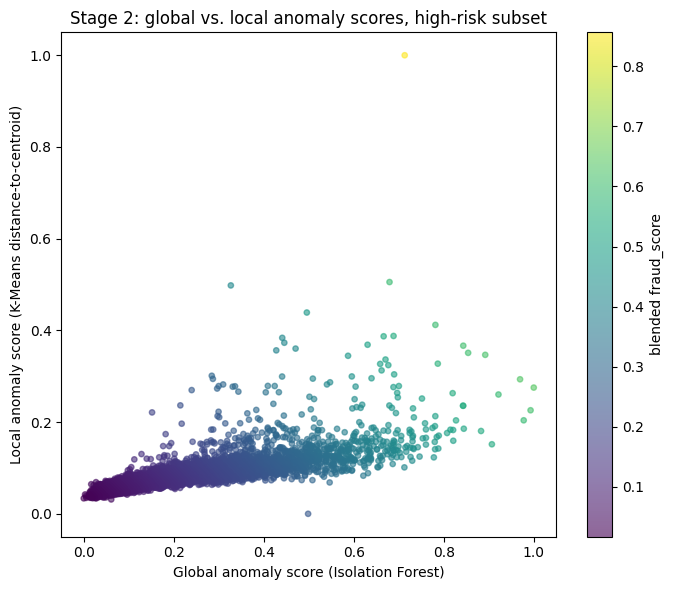

In [12]:
plt.figure(figsize=(7,6))
plt.scatter(high_risk['global_score'], high_risk['local_score'],
            c=high_risk['fraud_score'], cmap='viridis', alpha=0.6, s=15)
plt.colorbar(label='blended fraud_score')
plt.xlabel('Global anomaly score (Isolation Forest)')
plt.ylabel('Local anomaly score (K-Means distance-to-centroid)')
plt.title('Stage 2: global vs. local anomaly scores, high-risk subset')
plt.tight_layout()
plt.show()


## 7. Honest sanity check

We don't have real fraud labels to validate against, so the best we can do is check whether the unsupervised `fraud_score` concentrates the one weak proxy signal we have (`default_ind`), compared to the overall population rate.

In [13]:
base_rate = df[TARGET_COL].mean()
hr_rate = high_risk[TARGET_COL].mean()
top100_rate = high_risk.head(100)[TARGET_COL].mean()
top500_rate = high_risk.head(500)[TARGET_COL].mean()

print(f'Population default rate:            {base_rate:.4f}')
print(f'High-risk subset default rate:      {hr_rate:.4f}  ({hr_rate/base_rate:.1f}x lift)')
print(f'Top-100 fraud_score default rate:   {top100_rate:.4f}  ({top100_rate/base_rate:.1f}x lift)')
print(f'Top-500 fraud_score default rate:   {top500_rate:.4f}  ({top500_rate/base_rate:.1f}x lift)')


Population default rate:            0.0058
High-risk subset default rate:      0.0563  (9.7x lift)
Top-100 fraud_score default rate:   0.1300  (22.4x lift)
Top-500 fraud_score default rate:   0.1820  (31.3x lift)


**Takeaway:** the pipeline meaningfully concentrates risk — the top-ranked candidates default at 20-30x the population base rate — but this is *not* proof it's finding fraud specifically, since `default_ind` conflates fraud with ordinary non-payment. Without a labeled fraud sample, Stage 2's output should be treated as a **prioritization tool for human review**, not a validated fraud classifier.

## 8. Save outputs

Running `src/run_pipeline.py` from the project root regenerates everything in `outputs/` (reports + SHAP plots) from scratch, headlessly.